# 02 · Preprocesamiento y extracción de features (UCF-Crime 320, 3 clases)

Documenta el pipeline de datos de la tesis, leyendo los artefactos reales del repo:

| Paso | Artefacto |
|---|---|
| Versionado del dataset | `data/manifests_320/*.json`, `metadata.json` |
| Splits train/val/test e integridad | `data/processed/ucf_crime_3class_320/splits/*.jsonl` |
| Filtro de calidad (brillo) | `excluded_videos.csv` |
| Frames 320×240 | `data/raw/ucf_crime_320/{Train,Test}/<clase>/<video>_<idx>.jpg` |
| Muestreo temporal (L=16) y representación de movimiento | se recalcula aquí sobre ejemplos |
| Features pre-extraídas (5 variantes) | `data/processed/features/<variante>/*.npz` |

> La lógica oficial vive en los `.py` del repo; este notebook la **ejecuta y muestra**.

## 0. Configuración

In [3]:
import os, re, json, random
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR      = ROOT / "data/raw/ucf_crime_320"
PROC_DIR     = ROOT / "data/processed/ucf_crime_3class_320"
FEAT_DIR     = ROOT / "data/processed/features"
MANIFEST_DIR = ROOT / "data/manifests_320"

L_SEGMENTS = 16
IMG_SIZE = 224
BRIGHTNESS_THR = 30

for p in [RAW_DIR, PROC_DIR, FEAT_DIR, MANIFEST_DIR]:
    print("OK " if p.exists() else "NO ", p.relative_to(ROOT))

OK  data\raw\ucf_crime_320
OK  data\processed\ucf_crime_3class_320
OK  data\processed\features
OK  data\manifests_320


## 1. Versionado del dataset

In [4]:
def show_json(p, n=1200):
    if not p.exists():
        print("No existe:", p.relative_to(ROOT)); return
    txt = json.dumps(json.load(open(p, encoding="utf-8")), indent=2, ensure_ascii=False)
    print(f"--- {p.relative_to(ROOT)} ---")
    print(txt[:n] + ("\n..." if len(txt) > n else ""))

for p in [MANIFEST_DIR / "raw_dataset_version.json",
          MANIFEST_DIR / "processed_dataset_version.json",
          PROC_DIR / "metadata.json"]:
    show_json(p)

--- data\manifests_320\raw_dataset_version.json ---
{
  "dataset": "UCF-Crime (videos originales → frames 320×240)",
  "source_url": "https://www.crcv.ucf.edu/projects/real-world/",
  "download_date": "2026-10-01",
  "ingested_at": "2026-10-01T20:32:32+00:00",
  "raw_dir": "data/raw/ucf_crime_320",
  "hash_mode": "sha256 por archivo",
  "dataset_sha256": "b5624813ff432dbb39fb6c7050aab133e07f564af938239a1d44a39c1a4e7b0d",
  "totals": {
    "videos": 1650,
    "frames": 1306972,
    "bytes": 42938383931,
    "bytes_human": "40.0 GB"
  },
  "per_split": {
    "Test": {
      "videos": 239,
      "frames": 97650,
      "bytes": 3124799692
    },
    "Train": {
      "videos": 1411,
      "frames": 1209322,
      "bytes": 39813584239
    }
  },
  "per_category": {
    "Test/Abuse": {
      "videos": 2,
      "frames": 297,
      "bytes": 9388121,
      "sha256": "1edc01badf40b0da42edc51390153079c9978d0701aac7e019c75d97ef73f399"
    },
    "Test/Arson": {
      "videos": 9,
      "frames": 2

## 2. Splits train / val / test

In [5]:
dfs = []
for f in sorted((PROC_DIR / "splits").glob("*.jsonl")):
    d = pd.read_json(f, lines=True)
    d["split"] = f.stem
    dfs.append(d)
splits = pd.concat(dfs, ignore_index=True)
print("Columnas:", splits.columns.tolist())
splits.head()

Columnas: ['video_id', 'ucf_category', 'class_name', 'source_split', 'label', 'n_frames', 'brightness', 'frame_indices', 'frames', 'split']


,video_id,ucf_category,class_name,source_split,label,n_frames,brightness,frame_indices,frames,split
0,Normal_Videos_003_x264,NormalVideos,NormalVideos,Test,0,283,68.6,"[0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 1...",[Test/NormalVideos/Normal_Videos_003_x264_0.jp...,test
1,Normal_Videos_006_x264,NormalVideos,NormalVideos,Test,0,45,100.5,"[0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 1...",[Test/NormalVideos/Normal_Videos_006_x264_0.jp...,test
2,Normal_Videos_010_x264,NormalVideos,NormalVideos,Test,0,106,52.2,"[0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 1...",[Test/NormalVideos/Normal_Videos_010_x264_0.jp...,test
3,Normal_Videos_014_x264,NormalVideos,NormalVideos,Test,0,150,92.5,"[0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 1...",[Test/NormalVideos/Normal_Videos_014_x264_0.jp...,test
4,Normal_Videos_015_x264,NormalVideos,NormalVideos,Test,0,48,87.6,"[0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 1...",[Test/NormalVideos/Normal_Videos_015_x264_0.jp...,test


LABEL_COL = class_name | VIDEO_COL = video_id


split,test,train,val,All
class_name,,,,
Fighting,10,110,28,148
NormalVideos,150,160,40,350
Vandalism,77,120,30,227
All,237,390,98,725


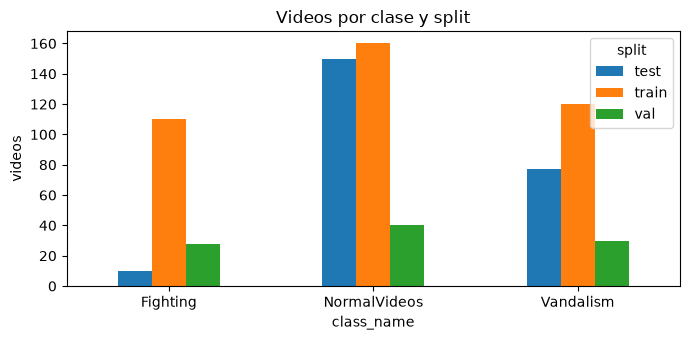

In [6]:
def pick_col(df, keys, exclude=()):
    for k in keys:
        for c in df.columns:
            if k in c.lower() and c not in exclude and c != "split":
                return c
    raise KeyError(f"No encontré columna con {keys}. Columnas: {df.columns.tolist()}")

# Si alguna detección no es la correcta, fíjala a mano, p. ej. LABEL_COL = "label_name"
LABEL_COL = pick_col(splits, ["macro", "label_name", "class_name", "clase", "label", "class", "category"])
VIDEO_COL = pick_col(splits, ["video_id", "video", "name", "path", "file", "id"], exclude=(LABEL_COL,))
print("LABEL_COL =", LABEL_COL, "| VIDEO_COL =", VIDEO_COL)

splits["video_id"] = splits[VIDEO_COL].astype(str).map(lambda s: Path(s.replace("\\", "/")).stem)

ct = pd.crosstab(splits[LABEL_COL], splits["split"], margins=True)
display(ct)
ct.drop(index="All").drop(columns="All").plot.bar(figsize=(7, 3.5), title="Videos por clase y split")
plt.ylabel("videos"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**Integridad del test set:** ningún video debe aparecer en más de un split.

In [7]:
sets = {s: set(g.video_id) for s, g in splits.groupby("split")}
names = sorted(sets)
for i, a in enumerate(names):
    for b in names[i + 1:]:
        print(f"{a:>6} ∩ {b:<6}: {len(sets[a] & sets[b])} videos en común")
print("Duplicados dentro de un mismo split:", splits.duplicated(["split", "video_id"]).sum())

  test ∩ train : 0 videos en común
  test ∩ val   : 0 videos en común
 train ∩ val   : 0 videos en común
Duplicados dentro de un mismo split: 0


## 3. Filtro de calidad: videos excluidos

In [8]:
exc = pd.read_csv(PROC_DIR / "excluded_videos.csv")
print("Videos excluidos:", len(exc))
display(exc.head())
for c in exc.columns:
    if exc[c].dtype == object and 1 < exc[c].nunique() <= 20:
        display(exc[c].value_counts().rename(f"conteo por {c}"))

Videos excluidos: 16


,video_id,ucf_category,class_name,source_split,reason,n_frames,brightness
0,Arson018_x264,Arson,Vandalism,Test,oscuro,85,29.9
1,Burglary037_x264,Burglary,Vandalism,Test,oscuro,192,29.9
2,Abuse032_x264,Abuse,Fighting,Train,oscuro,475,28.5
3,Assault052_x264,Assault,Fighting,Train,oscuro,79,29.2
4,Burglary090_x264,Burglary,Vandalism,Train,oscuro,277,26.1


## 4. Índice de frames 320×240

In [9]:
FRAME_RE = re.compile(r"^(.*)_(\d+)\.(jpg|jpeg|png)$", re.I)
frame_index = defaultdict(list)
video_meta = {}

for split_dir in RAW_DIR.iterdir():
    if not split_dir.is_dir():
        continue
    for cls_dir in split_dir.iterdir():
        if not cls_dir.is_dir():
            continue
        with os.scandir(cls_dir) as it:
            for e in it:
                m = FRAME_RE.match(e.name)
                if m:
                    frame_index[m.group(1)].append((int(m.group(2)), e.path))
                    video_meta.setdefault(m.group(1), (split_dir.name, cls_dir.name))
for v in frame_index:
    frame_index[v].sort()

raw = pd.DataFrame([{"video_id": v, "raw_split": s, "clase_original": c, "n_frames": len(frame_index[v])}
                    for v, (s, c) in video_meta.items()])
print(f"Videos con frames: {len(raw)} | frames totales: {raw.n_frames.sum():,}")
raw.groupby("clase_original").n_frames.describe().round(1)

Videos con frames: 1650 | frames totales: 1,306,972


,count,mean,std,min,25%,50%,75%,max
clase_original,,,,,,,,
Abuse,50.0,387.5,468.2,30.0,145.2,269.5,438.0,2848.0
Arson,50.0,544.3,1761.3,39.0,135.2,253.5,414.8,12656.0
Assault,50.0,260.3,289.2,14.0,80.5,179.0,306.8,1618.0
Burglary,100.0,471.6,678.1,30.0,131.0,277.0,558.2,4863.0
Explosion,50.0,505.3,1990.4,28.0,81.2,168.0,280.8,14190.0
Fighting,50.0,518.3,585.2,81.0,215.8,354.0,618.2,3165.0
NormalVideos,950.0,1066.0,4561.0,21.0,110.2,215.5,486.0,97651.0
Robbery,150.0,282.2,251.5,28.0,121.5,197.0,349.0,1528.0
Shoplifting,50.0,649.2,1058.1,45.0,184.2,277.5,674.8,6670.0


In [10]:
df = splits.merge(raw, on="video_id", how="left", suffixes=("_split", ""))
print("Columnas tras el merge:", df.columns.tolist())

faltan = df.n_frames.isna().sum()
print("Videos del split sin frames encontrados:", faltan)
if faltan:
    display(df[df.n_frames.isna()].head())

# Consistencia: frames declarados en el split vs. frames en disco
if "n_frames_split" in df.columns:
    dif = (df.n_frames_split - df.n_frames).abs()
    print("Videos con distinto n° de frames (split vs disco):", (dif > 0).sum())

print("Remapeo clase original -> macro-clase:")
display(pd.crosstab(df.clase_original, df[LABEL_COL]))
df.groupby(LABEL_COL).n_frames.describe().round(1)

Columnas tras el merge: ['video_id', 'ucf_category', 'class_name', 'source_split', 'label', 'n_frames_split', 'brightness', 'frame_indices', 'frames', 'split', 'raw_split', 'clase_original', 'n_frames']
Videos del split sin frames encontrados: 0
Videos con distinto n° de frames (split vs disco): 0
Remapeo clase original -> macro-clase:


class_name,Fighting,NormalVideos,Vandalism
clase_original,,,
Abuse,49,0,0
Arson,0,0,22
Assault,49,0,0
Burglary,0,0,39
Explosion,0,0,29
Fighting,50,0,0
NormalVideos,0,350,0
Robbery,0,0,64
Shoplifting,0,0,26


,count,mean,std,min,25%,50%,75%,max
class_name,,,,,,,,
Fighting,148.0,390.2,475.1,14.0,131.8,252.5,439.8,3165.0
NormalVideos,350.0,1012.3,4441.8,21.0,108.2,203.5,460.0,62802.0
Vandalism,227.0,402.7,972.4,30.0,136.0,229.0,436.0,14190.0


## 5. Brillo medio: excluidos vs. aceptados
Métrica: media del canal V (HSV) sobre 10 frames equiespaciados; umbral = 30. Si `filter_dataset_3class.py` usa otra métrica, reemplaza `mean_brightness`.

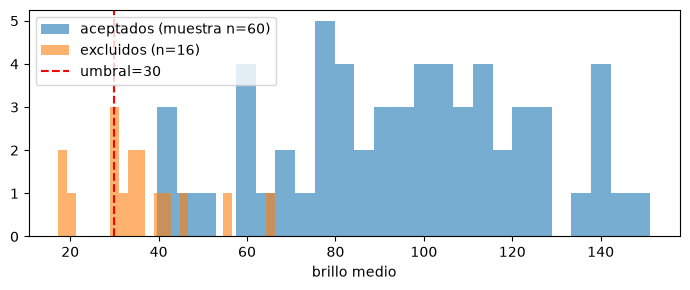

In [11]:
def read_rgb(path, size=None):
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    return cv2.resize(img, (size, size)) if size else img

def mean_brightness(vid, n=10):
    fr = frame_index[vid]
    idx = np.linspace(0, len(fr) - 1, min(n, len(fr))).astype(int)
    return float(np.mean([cv2.cvtColor(cv2.imread(fr[i][1]), cv2.COLOR_BGR2HSV)[..., 2].mean() for i in idx]))

EXC_VIDEO_COL = pick_col(exc, ["video_id", "video", "name", "path", "file", "id"])
exc["video_id"] = exc[EXC_VIDEO_COL].astype(str).map(lambda s: Path(s.replace("\\", "/")).stem)
exc_ok = [v for v in exc.video_id if v in frame_index]

ok = df.dropna(subset=["n_frames"])
def sample_per_class(d, n):
    return d.sample(frac=1, random_state=SEED).groupby(LABEL_COL).head(n)

acep = sample_per_class(ok, 20).video_id.tolist()
b_acep = pd.Series({v: mean_brightness(v) for v in acep})
b_exc = pd.Series({v: mean_brightness(v) for v in exc_ok[:60]})

plt.figure(figsize=(7, 3))
plt.hist(b_acep, bins=25, alpha=.6, label=f"aceptados (muestra n={len(b_acep)})")
if len(b_exc):
    plt.hist(b_exc, bins=25, alpha=.6, label=f"excluidos (n={len(b_exc)})")
plt.axvline(BRIGHTNESS_THR, color="red", ls="--", label=f"umbral={BRIGHTNESS_THR}")
plt.xlabel("brillo medio"); plt.legend(); plt.tight_layout(); plt.show()

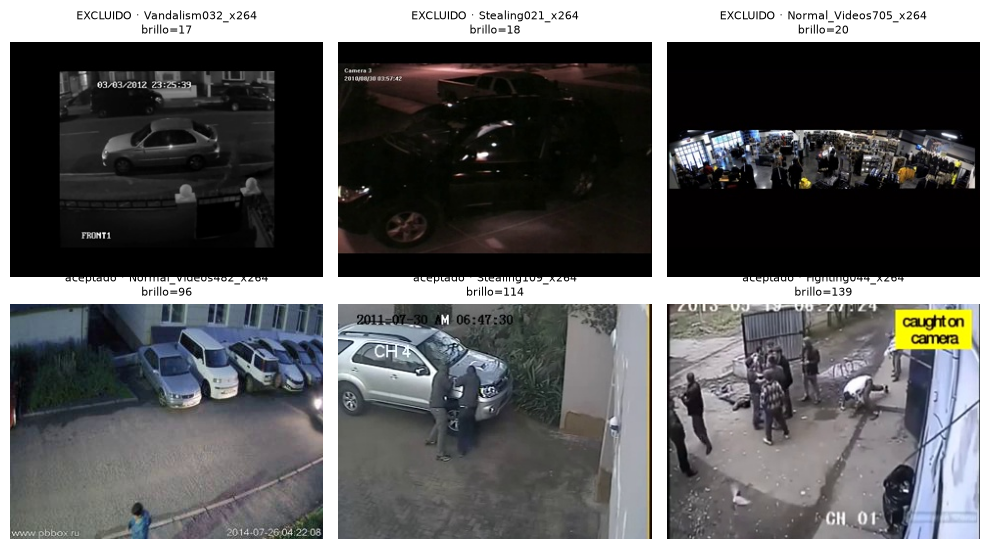

In [12]:
def mid_frame(vid, size=None):
    fr = frame_index[vid]
    return read_rgb(fr[len(fr) // 2][1], size)

ej_exc = b_exc.sort_values().index[:3].tolist()
ej_acep = b_acep.sample(min(3, len(b_acep)), random_state=SEED).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(10, 5.5))
for ax in axes.flat:
    ax.axis("off")
for ax, v in zip(axes[0], ej_exc):
    ax.imshow(mid_frame(v)); ax.set_title(f"EXCLUIDO · {v}\nbrillo={b_exc[v]:.0f}", fontsize=8)
for ax, v in zip(axes[1], ej_acep):
    ax.imshow(mid_frame(v)); ax.set_title(f"aceptado · {v}\nbrillo={b_acep[v]:.0f}", fontsize=8)
plt.tight_layout(); plt.show()

## 6. Muestreo temporal: L = 16 segmentos
El video se divide en 16 segmentos iguales y se toma 1 frame por segmento (centro en evaluación, aleatorio dentro del segmento en entrenamiento).

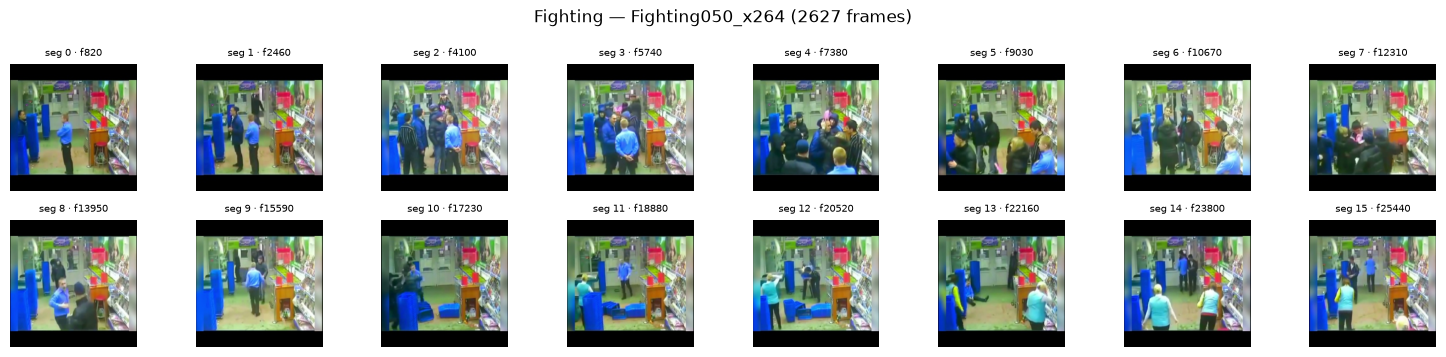

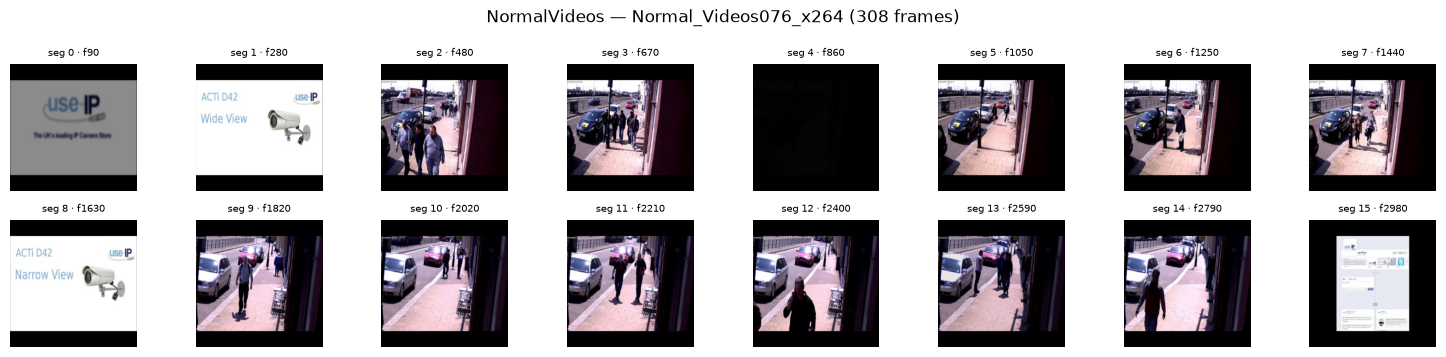

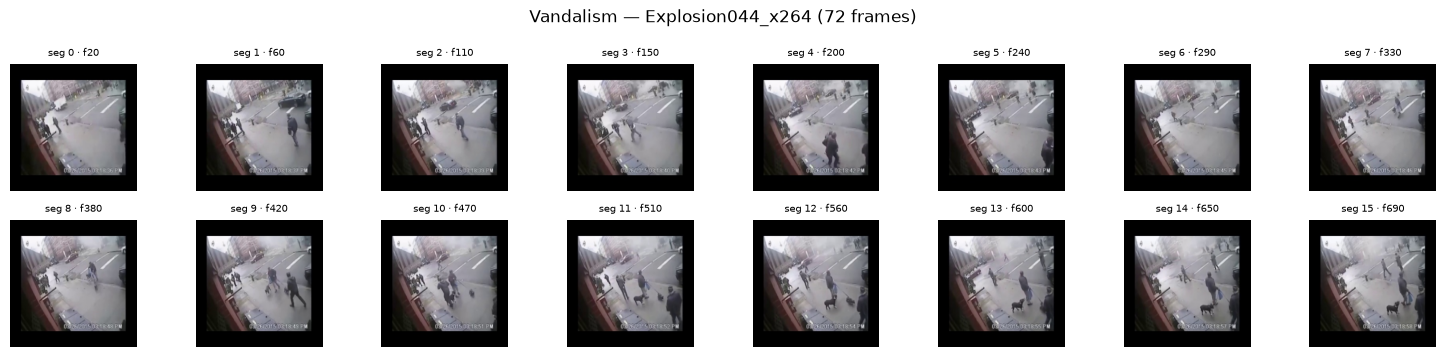

In [13]:
def sample_segments(n_frames, L=L_SEGMENTS, train=False):
    edges = np.linspace(0, n_frames, L + 1)
    if train:
        return np.array([np.random.randint(int(a), max(int(a) + 1, int(b))) for a, b in zip(edges[:-1], edges[1:])])
    return ((edges[:-1] + edges[1:]) / 2).astype(int).clip(0, n_frames - 1)

train_df = ok[ok.split.str.lower() == "train"]
demo = sample_per_class(train_df, 1).sort_values(LABEL_COL)

for _, r in demo.iterrows():
    fr = frame_index[r.video_id]
    idx = sample_segments(len(fr))
    fig, axes = plt.subplots(2, 8, figsize=(15, 3.6))
    for k, ax in enumerate(axes.flat):
        ax.imshow(read_rgb(fr[idx[k]][1], IMG_SIZE)); ax.set_title(f"seg {k} · f{fr[idx[k]][0]}", fontsize=7); ax.axis("off")
    fig.suptitle(f"{r[LABEL_COL]} — {r.video_id} ({len(fr)} frames)")
    plt.tight_layout(); plt.show()

## 7. Representaciones de movimiento: diferencia de frames vs. Farneback
Son las dos variantes de las features pre-extraídas (`*_diff_*` y `*_farneback_*`). Se calculan entre el frame muestreado y el siguiente.

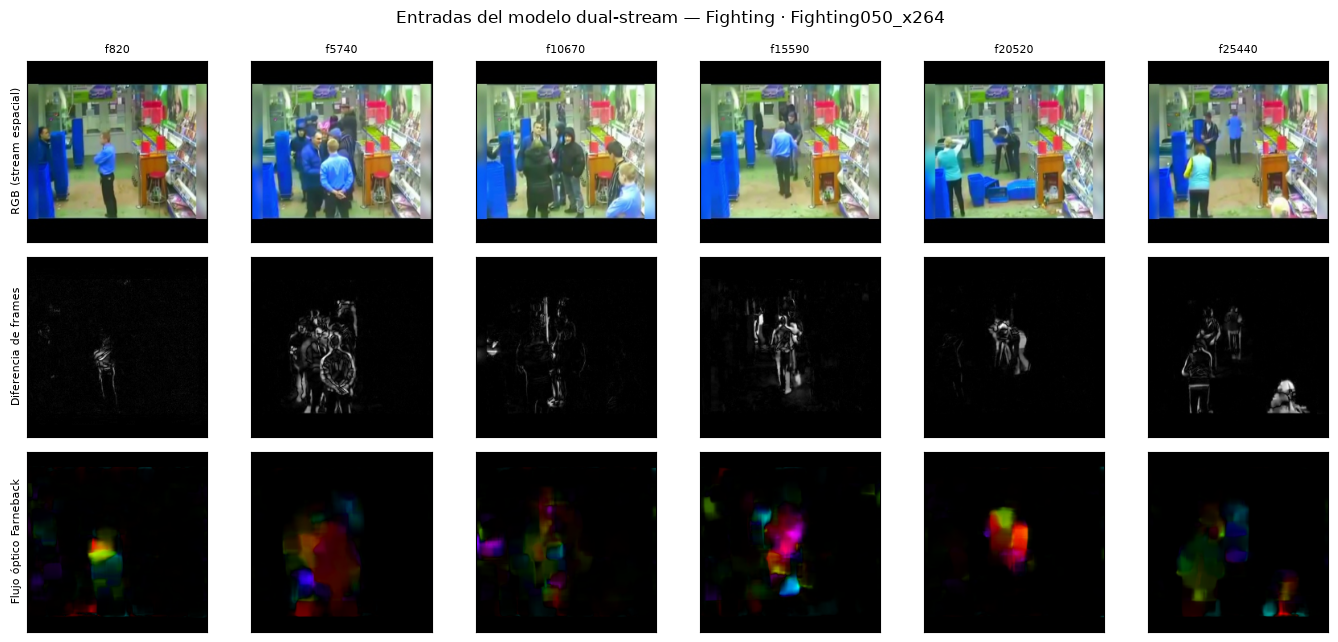

In [14]:
def motion_pair(a_rgb, b_rgb):
    a = cv2.cvtColor(a_rgb, cv2.COLOR_RGB2GRAY); b = cv2.cvtColor(b_rgb, cv2.COLOR_RGB2GRAY)
    diff = cv2.absdiff(b, a)
    flow = cv2.calcOpticalFlowFarneback(a, b, None, 0.5, 3, 15, 3, 5, 1.2, 0)
    mag, ang = cv2.cartToPolar(flow[..., 0], flow[..., 1])
    hsv = np.zeros((*a.shape, 3), np.uint8)
    hsv[..., 0] = ang * 180 / np.pi / 2; hsv[..., 1] = 255
    hsv[..., 2] = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)
    return diff, cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

anom = demo[~demo[LABEL_COL].astype(str).str.lower().str.startswith("normal")]
r = (anom if len(anom) else demo).iloc[0]
fr = frame_index[r.video_id]
idx = sample_segments(len(fr))[::3][:6]

fig, axes = plt.subplots(3, len(idx), figsize=(2.3 * len(idx), 6.5))
for k, i in enumerate(idx):
    a = read_rgb(fr[i][1], IMG_SIZE); b = read_rgb(fr[min(i + 1, len(fr) - 1)][1], IMG_SIZE)
    d, f = motion_pair(a, b)
    axes[0, k].imshow(a); axes[1, k].imshow(d, cmap="gray"); axes[2, k].imshow(f)
    axes[0, k].set_title(f"f{fr[i][0]}", fontsize=8)
for row, name in enumerate(["RGB (stream espacial)", "Diferencia de frames", "Flujo óptico Farneback"]):
    axes[row, 0].set_ylabel(name, fontsize=8)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"Entradas del modelo dual-stream — {r[LABEL_COL]} · {r.video_id}")
plt.tight_layout(); plt.show()

## 8. Features pre-extraídas
Cada variante combina un backbone (CLIP ViT-B/16 o ConvNeXt-S/T) con una representación de movimiento (diff o Farneback). Un `.npz` por video.

In [15]:
rows = []
for vdir in sorted(p for p in FEAT_DIR.iterdir() if p.is_dir()):
    files = sorted(vdir.glob("*.npz"))
    row = {"variante": vdir.name, "n_videos": len(files)}
    if files:
        z = np.load(files[0], allow_pickle=True)
        row["arrays (ej.)"] = ", ".join(f"{k}{tuple(z[k].shape)}:{z[k].dtype}" for k in z.files)
        row["MB total"] = round(sum(f.stat().st_size for f in files) / 1e6, 1)
    rows.append(row)
feat_summary = pd.DataFrame(rows)
feat_summary

,variante,n_videos,arrays (ej.),MB total
0,clipb16_t_diff_320,725,"rgb(273, 768):float16, mot(273, 768):float16, ...",1551.3
1,clipb16_t_farneback_320,725,"rgb(273, 768):float16, mot(273, 768):float16, ...",1551.3
2,convnext_s_t_diff,725,"rgb(273, 768):float16, mot(273, 768):float16, ...",1551.3
3,convnext_s_t_diff_320,725,"rgb(273, 768):float16, mot(273, 768):float16, ...",1551.3
4,convnext_s_t_farneback_320,725,"rgb(273, 768):float16, mot(273, 768):float16, ...",1551.3


In [16]:
VARIANT = "convnext_s_t_farneback_320"   # cambia para ver otra variante
show_json(FEAT_DIR / VARIANT / "index.json", n=1500)

--- data\processed\features\convnext_s_t_farneback_320\index.json ---
{
  "spatial_backbone": "convnext_small",
  "motion_backbone": "convnext_tiny",
  "pretrained": true,
  "img_size": 224,
  "dim_rgb": 768,
  "dim_mot": 768,
  "dtype": "float16",
  "motion_input": "farneback",
  "raft_model": null,
  "farneback_params": {
    "pyr_scale": 0.5,
    "levels": 3,
    "winsize": 15,
    "iterations": 3,
    "poly_n": 5,
    "poly_sigma": 1.2,
    "flags": 0
  },
  "flow_max_px": 20,
  "processed_dataset_sha256": "bd6157673f0d0e8c196d7a19a18e370fcd1604d9f8a84ad7f930709add97a5b8"
}


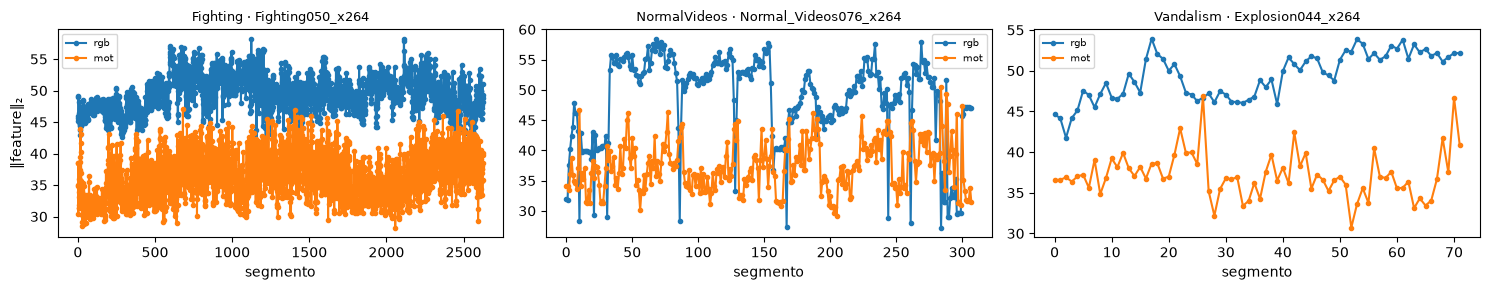

In [17]:
label_of = dict(zip(df.video_id, df[LABEL_COL]))
split_of = dict(zip(df.video_id, df.split))

def float_arrays(z):
    return {k: z[k].astype(np.float32) for k in z.files if z[k].dtype.kind == "f" and z[k].ndim >= 2}

# Perfil temporal: norma L2 por segmento de cada stream, para un video de cada clase
fig, axes = plt.subplots(1, len(demo), figsize=(5 * len(demo), 3), squeeze=False)
for ax, (_, r) in zip(axes[0], demo.iterrows()):
    f = FEAT_DIR / VARIANT / f"{r.video_id}.npz"
    if not f.exists():
        ax.set_title(f"sin features: {r.video_id}", fontsize=8); continue
    for k, a in float_arrays(np.load(f, allow_pickle=True)).items():
        ax.plot(np.linalg.norm(a.reshape(a.shape[0], -1), axis=1), marker=".", label=k)
    ax.set_title(f"{r[LABEL_COL]} · {r.video_id}", fontsize=9); ax.set_xlabel("segmento"); ax.legend(fontsize=7)
axes[0, 0].set_ylabel("‖feature‖₂")
plt.tight_layout(); plt.show()

**Separabilidad de clases:** embedding por video = promedio temporal de cada stream, concatenado; proyección PCA a 2D.

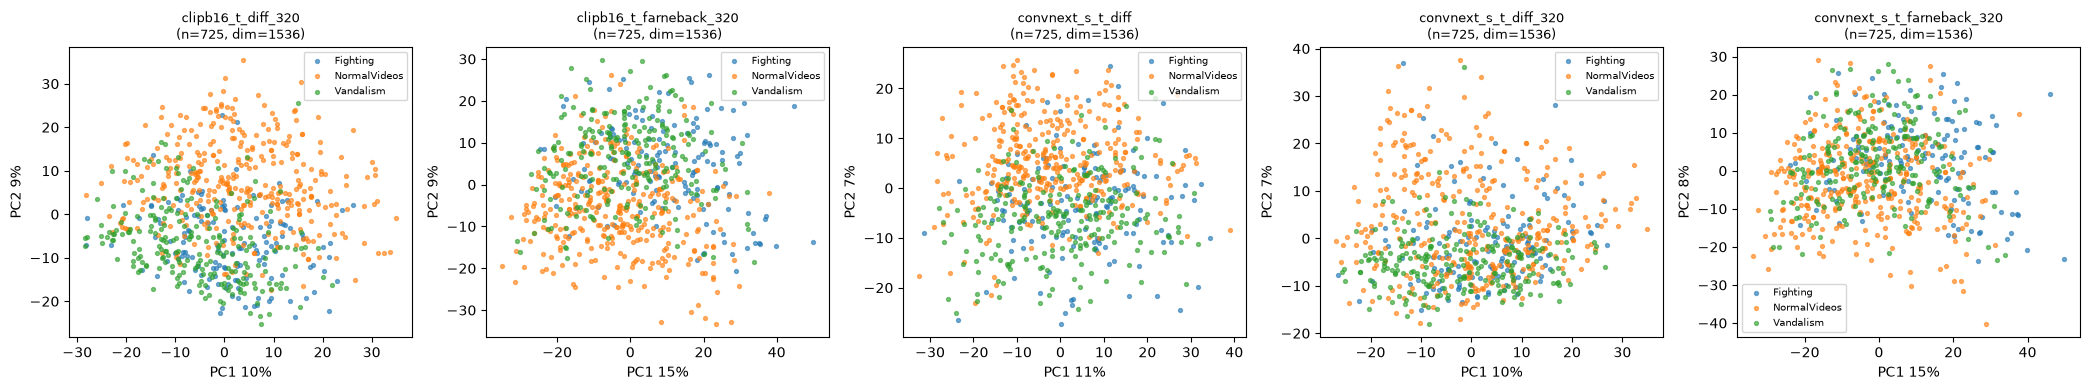

In [18]:
def video_embedding(path):
    parts = [a.reshape(a.shape[0], -1).mean(0) for a in float_arrays(np.load(path, allow_pickle=True)).values()]
    return np.concatenate(parts) if parts else None

def pca_plot(variant, ax):
    X, y = [], []
    for f in sorted((FEAT_DIR / variant).glob("*.npz")):
        if f.stem in label_of:
            e = video_embedding(f)
            if e is not None:
                X.append(e); y.append(str(label_of[f.stem]))
    if len(X) < 3:
        ax.set_title(f"{variant}: sin datos"); return
    X = np.stack(X); Xc = (X - X.mean(0)) / (X.std(0) + 1e-6)
    _, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    P = Xc @ Vt[:2].T; var = S**2 / (S**2).sum()
    y = np.array(y)
    for c in sorted(set(y)):
        ax.scatter(P[y == c, 0], P[y == c, 1], s=8, alpha=.6, label=c)
    ax.set_title(f"{variant}\n(n={len(X)}, dim={X.shape[1]})", fontsize=9)
    ax.set_xlabel(f"PC1 {var[0]:.0%}"); ax.set_ylabel(f"PC2 {var[1]:.0%}"); ax.legend(fontsize=7)

variants = [p.name for p in sorted(FEAT_DIR.iterdir()) if p.is_dir()]
fig, axes = plt.subplots(1, len(variants), figsize=(4.2 * len(variants), 4), squeeze=False)
for ax, v in zip(axes[0], variants):
    pca_plot(v, ax)
plt.tight_layout(); plt.show()

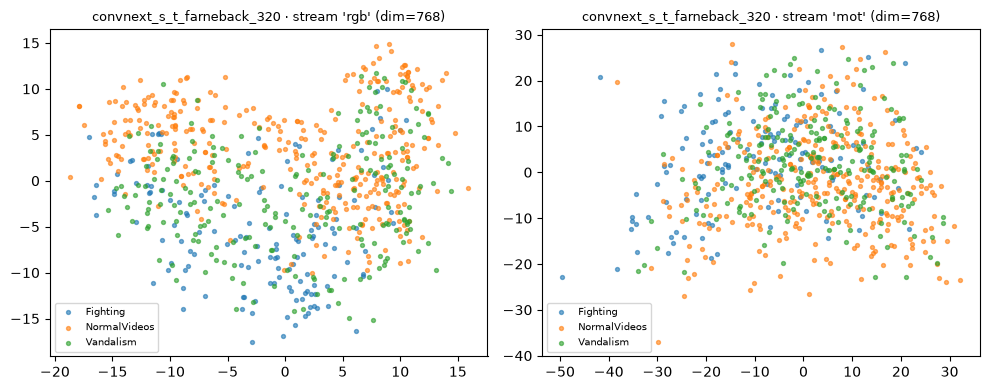

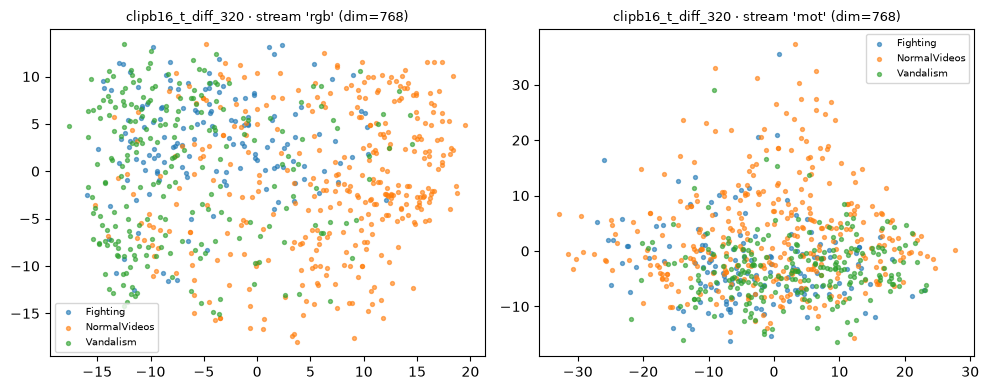

In [19]:
def pca_por_stream(variant):
    emb = defaultdict(list); y = []
    for f in sorted((FEAT_DIR / variant).glob("*.npz")):
        if f.stem not in label_of:
            continue
        arrs = float_arrays(np.load(f, allow_pickle=True))
        for k, a in arrs.items():
            emb[k].append(a.reshape(a.shape[0], -1).mean(0))
        y.append(str(label_of[f.stem]))
    y = np.array(y)
    fig, axes = plt.subplots(1, len(emb), figsize=(5 * len(emb), 4), squeeze=False)
    for ax, (k, X) in zip(axes[0], emb.items()):
        X = np.stack(X); Xc = (X - X.mean(0)) / (X.std(0) + 1e-6)
        _, S, Vt = np.linalg.svd(Xc, full_matrices=False); P = Xc @ Vt[:2].T
        for c in sorted(set(y)):
            ax.scatter(P[y == c, 0], P[y == c, 1], s=8, alpha=.6, label=c)
        ax.set_title(f"{variant} · stream '{k}' (dim={X.shape[1]})", fontsize=9); ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()

pca_por_stream("convnext_s_t_farneback_320")
pca_por_stream("clipb16_t_diff_320")

## 9. Resumen

In [21]:
resumen = {
    "Videos en splits": len(splits),
    "Por split": splits.split.value_counts().to_dict(),
    "Por clase": splits[LABEL_COL].value_counts().to_dict(),
    "Videos excluidos (calidad)": len(exc),
    "Fuga entre splits": sum(len(sets[a] & sets[b]) for i, a in enumerate(names) for b in names[i + 1:]),
    "Muestreo": f"{L_SEGMENTS} segmentos × 1 frame, {IMG_SIZE}×{IMG_SIZE}",
    "Variantes de features": variants,
}
for k, v in resumen.items():
    print(f"{k:28s}: {v}")

Videos en splits            : 725
Por split                   : {'train': 390, 'test': 237, 'val': 98}
Por clase                   : {'NormalVideos': 350, 'Vandalism': 227, 'Fighting': 148}
Videos excluidos (calidad)  : 16
Fuga entre splits           : 0
Muestreo                    : 16 segmentos × 1 frame, 224×224
Variantes de features       : ['clipb16_t_diff_320', 'clipb16_t_farneback_320', 'convnext_s_t_diff', 'convnext_s_t_diff_320', 'convnext_s_t_farneback_320']
